## 📊 Confusion Matrix – A Tool for Model Error Analysis

A **confusion matrix** is a vital evaluation metric that helps us understand **how well a classification model is performing**, especially when **accuracy alone is misleading**.

---

### 🔍 Why Do We Use a Confusion Matrix?

- Even if your model shows **high accuracy**, it might still be making serious **misclassifications**.
- The confusion matrix shows **where** the model is going wrong.
- It is constructed using:
  - `y_true`: the actual labels from the **test data**
  - `y_pred`: the predicted labels from the **model's output**

---

### 🤖 Real-life Analogy (Binary Example: Fever Detection)

Let’s assume we have a medical model that predicts if a person has **fever (1)** or **no fever (0)**:

| True Value | Predicted Value | Explanation                                   |
|------------|------------------|-----------------------------------------------|
| 0          | 0                | ✅ Correct: No fever, predicted correctly       |
| 0          | 1                | ❌ Wrong: Model predicted fever, but person didn’t have it |
| 1          | 0                | ❌ Wrong: Person had fever, but model missed it |
| 1          | 1                | ✅ Correct: Fever detected correctly            |

Cases 2 and 3 are dangerous:
- **Case 2 (False Positive)** → Person is wrongly told they are sick.
- **Case 3 (False Negative)** → Person is wrongly told they are healthy (this is **more critical**).

---

### 🔢 The Confusion Matrix Structure (Binary Classification)

For binary classification (e.g., Fever / No Fever), the matrix has 4 outcomes:

|               | Predicted: No (0) | Predicted: Yes (1) |
|---------------|------------------|--------------------|
| Actual: No (0) | ✅ **TN** (True Negative)   | ❌ **FP** (False Positive) |
| Actual: Yes (1)| ❌ **FN** (False Negative)  | ✅ **TP** (True Positive)  |

- **TP (True Positive)**: Model correctly predicts **1**
- **TN (True Negative)**: Model correctly predicts **0**
- **FP (False Positive)**: Model wrongly predicts 1 when it's 0
- **FN (False Negative)**: Model wrongly predicts 0 when it's 1

These **counts** help us understand the nature of errors.

---

### 📈 Confusion Matrix for Multiclass Classification

- Works similarly to binary but expands to a **square matrix** with one row/column for each class.
- For 3 flower types (`setosa`, `versicolor`, `virginica`), the matrix will be **3x3**.
- Each cell `[i][j]` shows how many times class `i` was predicted as class `j`.

---

### 🧮 Important Metrics Derived from Confusion Matrix

#### ✅ Accuracy
Measures overall correctness:

\[
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
\]

- **Interpretation**: Out of all predictions, how many were correct.

---

#### ❌ Error Rate
Measures overall incorrectness:

\[
\text{Error Rate} = \frac{FP + FN}{TP + TN + FP + FN}
\]

---

### ⚠️ Types of Errors

#### 1. **False Positive (FP)** – Type I Error
- Model gives a **positive** result for a person who doesn’t have the condition.
- Example: Diagnosing a healthy person with a disease.
- May lead to **unnecessary stress or treatment**.

#### 2. **False Negative (FN)** – Type II Error
- Model gives a **negative** result when the condition is actually present.
- Example: Failing to diagnose a sick patient.
- **More dangerous** in medical, safety, or security-critical systems.

---

### 🧠 Summary

| Term  | Meaning                                | Impact                           |
|-------|----------------------------------------|----------------------------------|
| TP    | Correctly predicted positive           | ✅ Desired outcome                |
| TN    | Correctly predicted negative           | ✅ Desired outcome                |
| FP    | Predicted positive, actually negative  | ⚠️ May be manageable              |
| FN    | Predicted negative, actually positive  | ❗ Can be fatal or high-risk      |

Even with high accuracy, **FN errors** can have critical consequences, especially in:
- Healthcare
- Security
- Autonomous vehicles

---


C:\Users\junai\AppData\Local\Temp\ipykernel_18492\1954775583.py:17: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = df_binary["species"].replace({'setosa': 0, 'versicolor': 1}).astype(int)


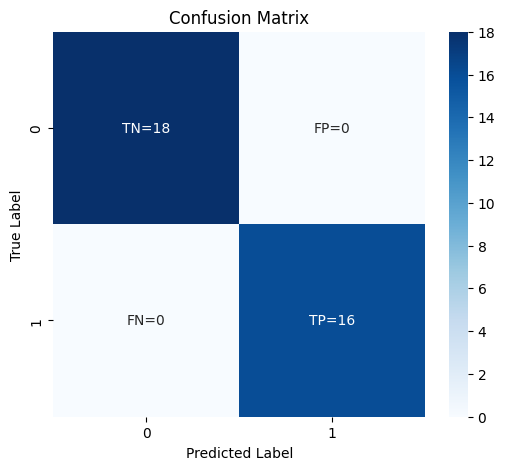

In [2]:
import pandas as pd
import numpy as np  # ✅ Needed for np.array
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

# Load data
df = pd.read_csv(r"C:\Users\junai\Desktop\coding\ML\flowers.csv")

# Keep only two classes for binary classification
df_binary = df[df['species'].isin(['setosa', 'versicolor'])]

# Features and target
x = df_binary.drop("species", axis=1)
y = df_binary["species"].replace({'setosa': 0, 'versicolor': 1}).astype(int)

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Train model
lr2 = LogisticRegression(max_iter=200)
lr2.fit(x_train, y_train)

# Predict and compute confusion matrix
y_pred = lr2.predict(x_test)
cm = confusion_matrix(y_test, y_pred)

# Label matrix like TP, FP, etc.
labels = [
    f"TN={cm[0, 0]}", f"FP={cm[0, 1]}",
    f"FN={cm[1, 0]}", f"TP={cm[1, 1]}"
]
labels = np.array(labels).reshape(2, 2)

# Plot
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', xticklabels=[0, 1], yticklabels=[0, 1])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()
